In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
import os
print("Current Dir", os.getcwd())
curr_dir = os.getcwd()   # this notebook lives in Potato_leaf_disease_Detection/Model
dataset_dir = os.path.join(curr_dir, "..", "Dataset")
train_path = os.path.join(dataset_dir, "Train")
test_path = os.path.join(dataset_dir, "Test")
valid_path = os.path.join(dataset_dir, "Valid")


Current Dir C:\Users\hp\OneDrive\Desktop\Data Science Clouldblitz\Projects\Potato_leaf_disease_Detection\Model


In [5]:
training_set = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 900 files belonging to 3 classes.


In [7]:
training_set.class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [9]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 300 files belonging to 3 classes.


In [11]:
cnn = tf.keras.models.Sequential()
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=[128, 128, 3]))
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=512, activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.3))

cnn.add(tf.keras.layers.Dense(units=3, activation='softmax'))

C:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [15]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 126, 126, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 127008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      65,028,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │           1,539 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 65,040,291 (248.11 MB)

 Trainable params: 65,040,291 (248.11 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
training_history=cnn.fit(training_set,validation_data=validation_set,epochs=10)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.3638 - loss: 240.9522 - val_accuracy: 0.6200 - val_loss: 8.9472
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.6573 - loss: 9.7321 - val_accuracy: 0.5667 - val_loss: 2.8247
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.7538 - loss: 1.8812 - val_accuracy: 0.7633 - val_loss: 0.5095
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.8583 - loss: 0.3852 - val_accuracy: 0.7800 - val_loss: 0.4637
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.8840 - loss: 0.2954 - val_accuracy: 0.6967 - val_loss: 0.6702
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.8402 - loss: 0.4572 - val_accuracy: 0.8667 - val_loss: 0.3220
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.9059 - loss: 0.2328 - val_accuracy: 0.8967 - val_loss: 0.2587
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.9141 - loss: 0.2225 - val_accuracy: 0.9000 - val_los

In [19]:
train_loss,train_acc = cnn.evaluate(training_set)
print("Training Accuracy",train_acc)

29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.9953 - loss: 0.0284
Training Accuracy 0.992222249507904


In [21]:
valid_loss,valid_acc = cnn.evaluate(validation_set)
print("Validation Accuracy",valid_acc)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 150ms/step - accuracy: 0.9207 - loss: 0.2015
Validation Accuracy 0.9066666960716248


In [23]:
cnn.save('trained_plant_disease_model.keras')

In [25]:
training_history.history

{'accuracy': [0.4055555462837219,
  0.6899999976158142,
  0.7799999713897705,
  0.851111114025116,
  0.8677777647972107,
  0.8577777743339539,
  0.9055555462837219,
  0.9166666865348816,
  0.9111111164093018,
  0.9655555486679077],
 'loss': [130.8944549560547,
  6.234200477600098,
  1.224034070968628,
  0.4033887982368469,
  0.34453535079956055,
  0.3648368716239929,
  0.23707206547260284,
  0.21289612352848053,
  0.22654025256633759,
  0.09642824530601501],
 'val_accuracy': [0.6200000047683716,
  0.5666666626930237,
  0.7633333206176758,
  0.7799999713897705,
  0.6966666579246521,
  0.8666666746139526,
  0.8966666460037231,
  0.8999999761581421,
  0.8966666460037231,
  0.9066666960716248],
 'val_loss': [8.947174072265625,
  2.824688673019409,
  0.509452223777771,
  0.4637161195278168,
  0.670210063457489,
  0.3220324218273163,
  0.2587357759475708,
  0.21859867870807648,
  0.3002687990665436,
  0.22820469737052917]}

In [27]:
test_set = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    image_size=(128, 128),
    shuffle=False,
)
test_loss, test_acc = cnn.evaluate(test_set)
print("Test Accuracy", test_acc)

Found 300 files belonging to 3 classes.
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 0.9342 - loss: 0.1736
Test Accuracy 0.9300000071525574


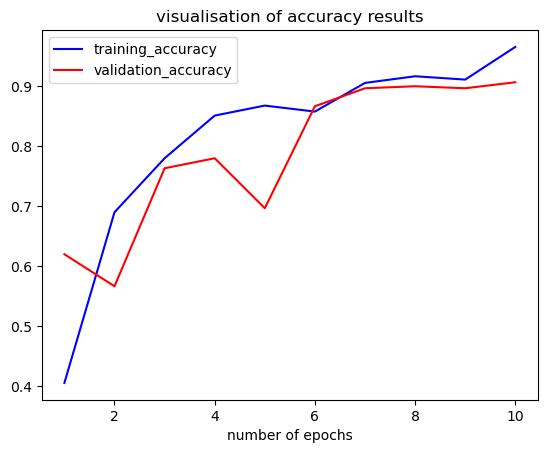

In [29]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='blue',label='training_accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='red',label='validation_accuracy')
plt.xlabel('number of epochs')
plt.title('visualisation of accuracy results')
plt.legend()
plt.show()